# Contacts of a solved ball bearing against an independent Hertz

**Case:** `validation/bearings/iso16281_ball_contact`
**Type:** implementation check, same theory (AxisForge `cp` is Hertz; the judge is Hertz)

For each load case the bearing is solved with the ISO/TS 16281 ball solver, every loaded ball
is handed to the bridge (`slippy_bridge.contact.contacts`: one contact per raceway, SI units,
rolling radius at the operating angle $\alpha_j$) and the independent Hertz
(`references.contact.hertz.hertz_point`) is evaluated on it.

Nothing is asserted here: every pass/fail criterion lives in `tests/` (see the README). This
script produces the table of real contacts ($Q_j$, $\alpha_j$, $p_0$, semi-axes, approach per
raceway) and reports two findings:

- **F0** AxisForge's total approach $\delta_j$ against the summed Hertz approach at $\alpha_0$:
  expected ratio $(1.48096/1.48)^{2/3} = 1.000433$ (rounded constant in `cp`).
- **F1** AxisForge evaluates the raceway curvatures at the free angle $\alpha_0$, the bridge at
  $\alpha_j$: effect on $p_0$ and on the approach, per raceway.

In [1]:
import math
import pathlib
from collections import defaultdict

import matplotlib.pyplot as plt
from IPython.display import display
from axisforge.outputs._format import format_table, write_records_csv
from axisforge.outputs.solvers.bearings.load_distribution.load_distribution_results import element_records
from axisforge.solvers.machine_elements.bearings.load_distribution.iso_16281.contact_solver import (
    ISO16281BallSolver,
)

from references.contact.hertz import hertz_point
from slippy_bridge.contact import contact_case, contacts
from slippy_bridge.contact.outputs import rel_err
from validation._support.figures import bearing_plots
from validation._support.style import use_style

import construction as cd

use_style()                                       # house paper style (style/README.md)

# the case folder: the script's own folder, or the working directory when run as a notebook
HERE = pathlib.Path(__file__).resolve().parent if "__file__" in globals() else pathlib.Path.cwd()
RESULTS = HERE / "results"                                          # git-ignored (D-0020)
RESULTS.mkdir(exist_ok=True)

## 1. Solve, extract the contacts, evaluate Hertz

AxisForge has no centrifugal term, so the inner and the outer contact of a ball carry the same
$Q_j$ and $\alpha_j$ and differ only in the raceway radii. The ellipse edge angle is the
contact angle plus the angle the semi-axis across rolling subtends on the groove,
$\alpha_j + s_y / |r_\mathrm{groove}|$: $s_y$ is taken as an arc; read as a tangent-plane
half-width (asin) the angle is about 0.5 deg larger. Measured about the groove centre of
curvature. Indicative only: at $s_y / r = 0.38$ Hertz is strained. AxisForge has no shoulder
geometry, so the angle is compared with nothing.

Each row starts from `Contact.record()`, which carries `label` and `case_hash`: the join key
with the static-step records of the BEM study.

In [2]:
contact_records, approach_records = [], []
elements = {}                                             # case -> element_records (figures, section 4)
for name, load in cd.LOADS.items():
    bearing = cd.build_bearing(load["s"])
    result = ISO16281BallSolver().solve_contact(bearing, Fr_xz=load["Fr"], Fr_xy=0.0, Fa=load["Fa"],
                                                delta_r_init=0.0, delta_a_init=0.0, psi=0.0, phi_Fr=0.0)
    approach_alpha0_m = defaultdict(float)                # Hertz, summed over both raceways, per ball [m]
    for c in contacts(bearing, result):                   # loaded balls, inner and outer raceway
        race, alpha_j = c.location["race"], c.location["alpha_rad"]
        judge = hertz_point(c.case.r1, c.case.r2, c.case.E, c.case.nu, c.case.load)
        # the same contact with the raceway radii as AxisForge stores them, at the free angle alpha_0
        at_alpha0 = contact_case(bearing, race, c.case.load)
        judge_alpha0 = hertz_point(at_alpha0.r1, at_alpha0.r2, at_alpha0.E, at_alpha0.nu, at_alpha0.load)
        approach_alpha0_m[c.location["element_j"]] += judge_alpha0["delta_m"]
        contact_records.append({
            "case": name, "solver_ok": bool(result.ok), **c.record(), "Q_N": c.case.load, **judge,
            "p0_alpha0_Pa": judge_alpha0["p0_Pa"], "delta_alpha0_m": judge_alpha0["delta_m"],
            "p0_alpha0_rel_diff": rel_err(judge_alpha0["p0_Pa"], judge["p0_Pa"]),
            "delta_alpha0_rel_diff": rel_err(judge_alpha0["delta_m"], judge["delta_m"]),
            # r2[1] is the groove radius [m], concave (negative): its magnitude. s_y as an arc.
            "edge_angle_rad": alpha_j + judge["s_y_m"] / abs(c.case.r2[1]),
        })
    elements[name] = element_records(result)
    for e in elements[name]:                              # AxisForge: delta_mm = approach of the two raceways
        if e["j"] in approach_alpha0_m:                   # loaded balls only
            approach_records.append({
                "case": name, "solver_ok": bool(result.ok), "j": e["j"], "Q_N": e["Q_N"],
                "delta_j_mm": e["delta_mm"], "delta_hertz_alpha0_m": approach_alpha0_m[e["j"]],
                # AxisForge [mm] -> [m], the only unit conversion of this script
                "delta_ratio": e["delta_mm"] * 1e-3 / approach_alpha0_m[e["j"]]})

write_records_csv(RESULTS / "contacts.csv", contact_records)
write_records_csv(RESULTS / "approach.csv", approach_records)

## 2. Contacts: load, angle, Hertz pressure, semi-axes and approach per raceway

`s_x` is the semi-axis along rolling, `s_y` across it (along the groove). The columns
"(a0)" repeat $p_0$ and the approach with the raceway radii at $\alpha_0$; "diff" is
(value at $\alpha_0$ - value at $\alpha_j$) / value at $\alpha_j$ (finding F1).

In [3]:
DEG = math.degrees(1.0)
CONTACT_COLUMNS = [
    ("case", "case", ""), ("race", "race", ""), ("element_j", "j", "d"),
    ("phi_local_rad", "phi [deg]", ".1f", DEG), ("Q_N", "Q [N]", ".1f"),
    ("alpha_rad", "alpha [deg]", ".3f", DEG), ("p0_Pa", "p0 [MPa]", ".1f", 1e-6),
    ("s_x_m", "s_x [mm]", ".4f", 1e3), ("s_y_m", "s_y [mm]", ".4f", 1e3),
    ("delta_m", "delta [um]", ".3f", 1e6),
    ("p0_alpha0_Pa", "p0 (a0) [MPa]", ".1f", 1e-6), ("p0_alpha0_rel_diff", "diff [%]", "+.3f", 100.0),
    ("delta_alpha0_m", "delta (a0) [um]", ".3f", 1e6), ("delta_alpha0_rel_diff", "diff [%]", "+.3f", 100.0),
    ("edge_angle_rad", "edge [deg]", ".2f", DEG),
]
print(format_table(CONTACT_COLUMNS, contact_records))

           case   race  j  phi [deg]   Q [N]  alpha [deg]  p0 [MPa]  s_x [mm]  s_y [mm]  delta [um]  p0 (a0) [MPa]  diff [%]  delta (a0) [um]  diff [%]  edge [deg]
---------------  -----  -  ---------  ------  -----------  --------  --------  --------  ----------  -------------  --------  ---------------  --------  ----------
radial_moderate  inner  0        0.0  1607.9        0.000    2193.8    0.1952    1.7932      13.402         2193.8    +0.000           13.402    +0.000       15.56
radial_moderate  outer  0        0.0  1607.9        0.000    1857.1    0.2372    1.7429      12.949         1857.1    +0.000           12.949    +0.000       15.12
radial_moderate  inner  1       40.0  1078.1        0.000    1920.1    0.1708    1.5695      10.267         1920.1    +0.000           10.267    +0.000       13.62
radial_moderate  outer  1       40.0  1078.1        0.000    1625.4    0.2076    1.5254       9.919         1625.4    +0.000            9.919    +0.000       13.23
radial_moderate 

## 3. Total approach: AxisForge against the summed Hertz approach at $\alpha_0$ (finding F0)

`Q_j = cp delta_j**1.5` with the constant 1.48 where Hertz gives $\pi\sqrt{2}/3 = 1.48096$, so
the ratio is expected to be 1.000433 for every ball and every load.

In [4]:
APPROACH_COLUMNS = [
    ("case", "case", ""), ("solver_ok", "solved", ""), ("j", "j", "d"), ("Q_N", "Q [N]", ".1f"),
    ("delta_j_mm", "delta_j AxisForge [um]", ".4f", 1e3),
    ("delta_hertz_alpha0_m", "Hertz inner+outer (a0) [um]", ".4f", 1e6),
    ("delta_ratio", "ratio", ".6f"),
]
print(format_table(APPROACH_COLUMNS, approach_records))
print(f"\nwritten: {(RESULTS / 'contacts.csv').relative_to(HERE)}, {(RESULTS / 'approach.csv').relative_to(HERE)}")

           case  solved  j   Q [N]  delta_j AxisForge [um]  Hertz inner+outer (a0) [um]     ratio
---------------  ------  -  ------  ----------------------  ---------------------------  --------
radial_moderate     yes  0  1607.9                 26.3622                      26.3508  1.000433
radial_moderate     yes  1  1078.1                 20.1946                      20.1859  1.000433
radial_moderate     yes  2   116.4                  4.5778                       4.5758  1.000433
radial_moderate     yes  7   116.4                  4.5778                       4.5758  1.000433
radial_moderate     yes  8  1078.1                 20.1946                      20.1859  1.000433
   radial_heavy     yes  0  4528.3                 52.5713                      52.5485  1.000433
   radial_heavy     yes  1  2839.9                 38.5172                      38.5006  1.000433
   radial_heavy     yes  2    59.6                  2.9313                       2.9300  1.000433
   radial_heavy     

## 4. Around the bearing: element loads and contact ellipses

Per load case, against the local azimuth $\varphi_j$ (0 on the load line): ball load $Q_j$, total
approach $\delta_j$ and contact angle $\alpha_j$ (AxisForge), then $p_0$, $s_x$, $s_y$ per raceway
(Hertz on the bridge contacts, section 1). Written to `results/01_element_loads_<case>.png` and
`results/01_contact_ellipses_<case>.png`. The combined case has an axial load given directly to
the solver ($\psi = 0$, no shaft path): A2 (R-003, R-101) does not enter here; the stamp is kept
by rule.

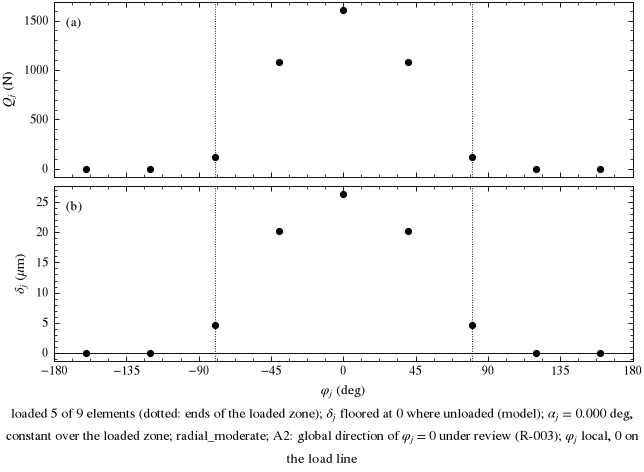

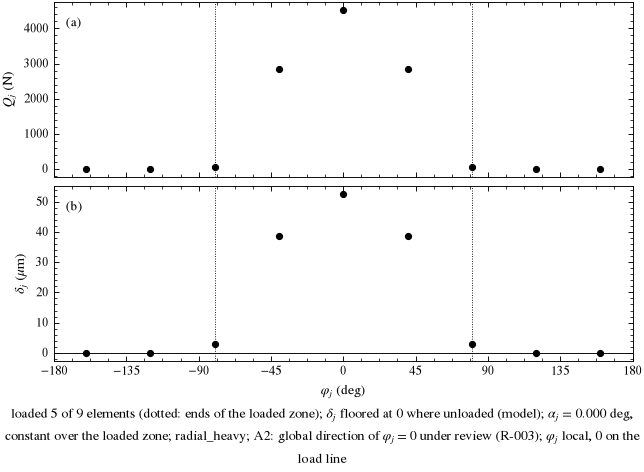

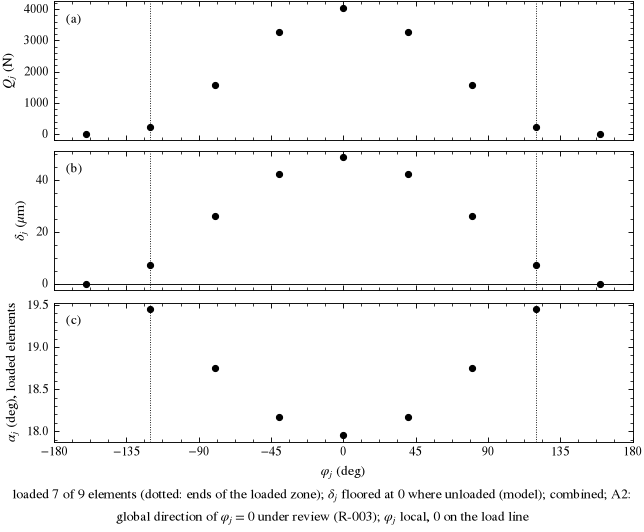

In [5]:
for name, recs in elements.items():
    fig = bearing_plots.element_loads([e["phi_rad"] for e in recs], [e["Q_N"] for e in recs],
                                      delta_mm=[e["delta_mm"] for e in recs], alpha_rad=[e["alpha_rad"] for e in recs],
                                      note=f"{name}; {bearing_plots.A2_NOTE}")
    fig.savefig(RESULTS / f"01_element_loads_{name}.png")
    display(fig)
    plt.close(fig)

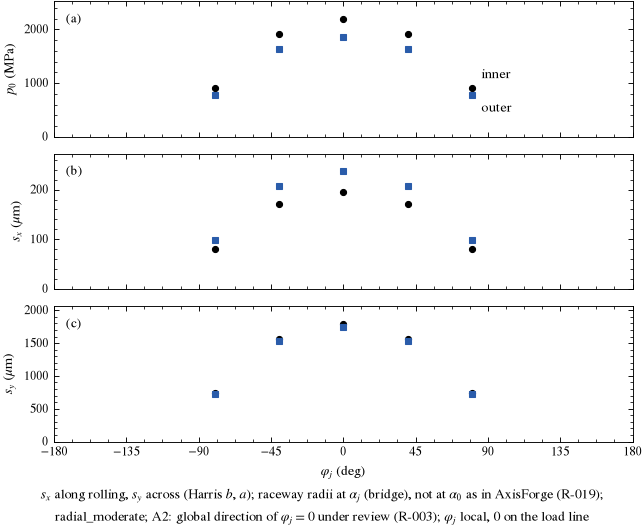

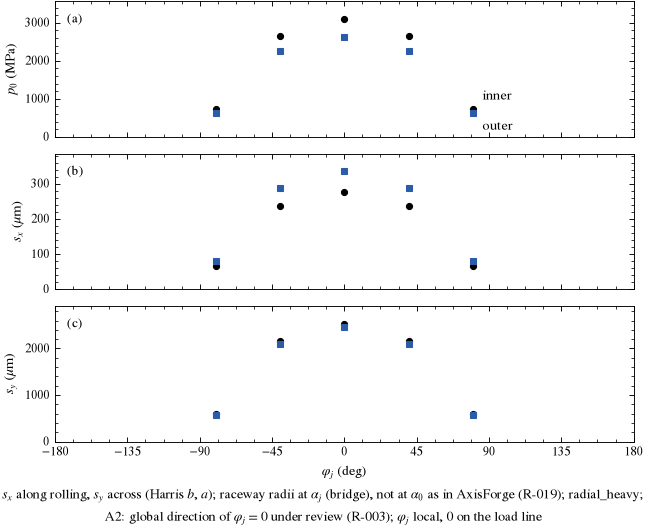

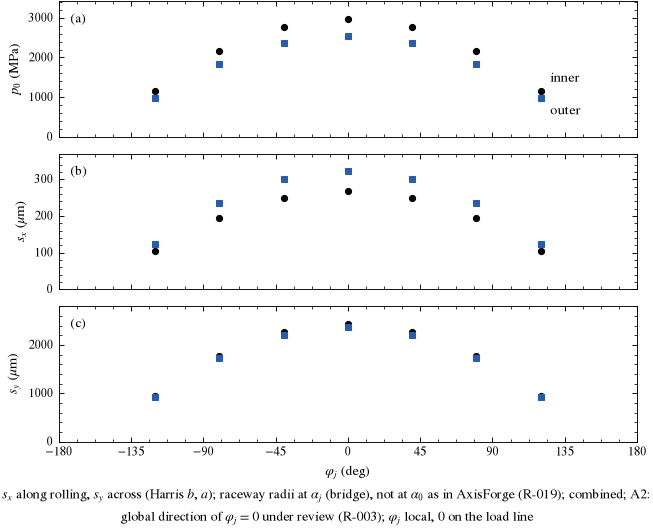

In [6]:
for name in elements:
    rows = [r for r in contact_records if r["case"] == name]
    fig = bearing_plots.contact_ellipses([r["phi_local_rad"] for r in rows], [r["race"] for r in rows],
                                         [r["p0_Pa"] for r in rows], [r["s_x_m"] for r in rows],
                                         [r["s_y_m"] for r in rows], note=f"{name}; {bearing_plots.A2_NOTE}")
    fig.savefig(RESULTS / f"01_contact_ellipses_{name}.png")
    display(fig)
    plt.close(fig)

## 5. The bearing in 3D: ball loads, Hertz pressures, contact angle (PyVista)

`viz.bearing.bearing_scene` reads the bearing and its solved result directly and builds a scene
(`pyvista.MultiBlock`): rings revolved from their section, balls at `phi_j_global`, one enlarged
contact ellipse per loaded ball and raceway (Hertz values through `slippy_bridge.contact`), load
arrows. `viz.scene.save` writes `results/viz/<case>.vtm` (ParaView) and one PNG per field, with a
fixed camera; the three load cases share the colour limits, so colours compare across figures.
`viz.scene.explore(scene, vb.FIELDS, clim=clim)` opens the same scene in a window with a field
selector.

`Fr` and `Fa` are drawn as given to the solver, read as the load on the inner ring; the balls are
drawn where `phi_j_global` puts them. Arrow and loaded zone are on the same side by construction
of the ball solver; this figure does not test the shaft path of the open review item on `phi_Fr`.
Between "moderate" and "heavy" both `Fr` and the diametral clearance `s` change.

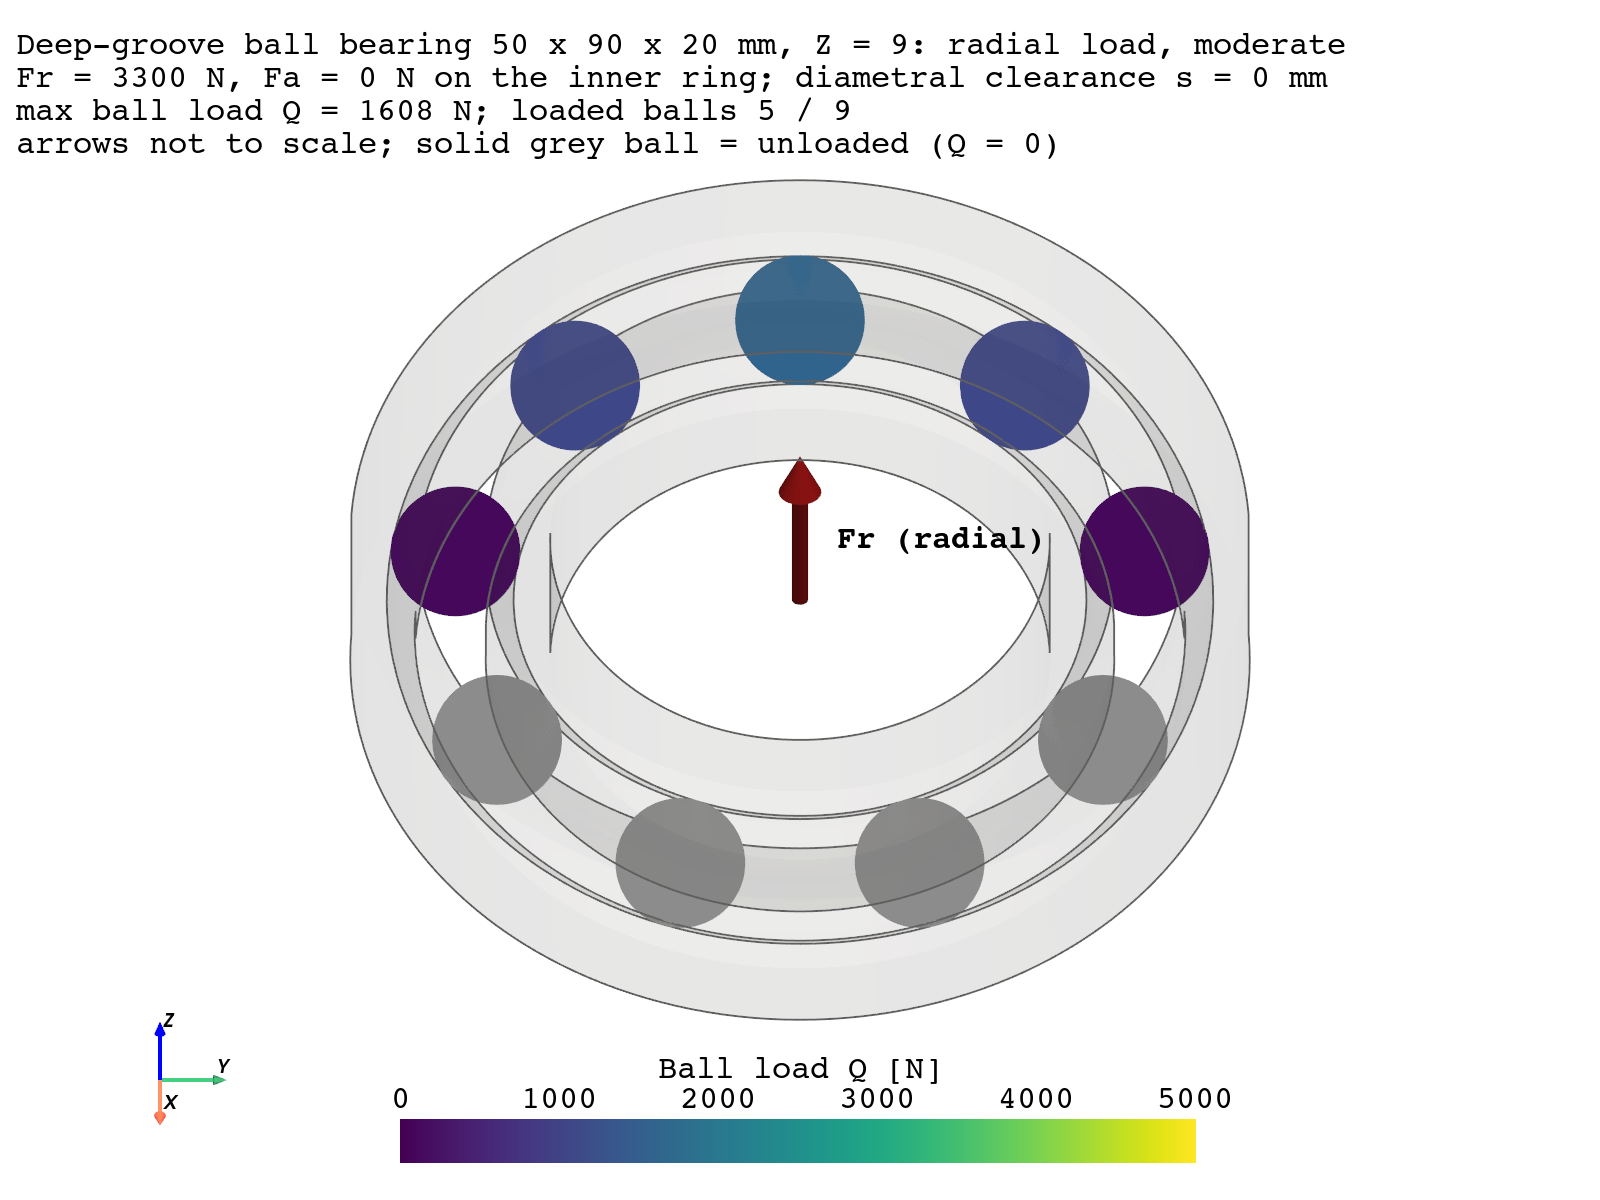

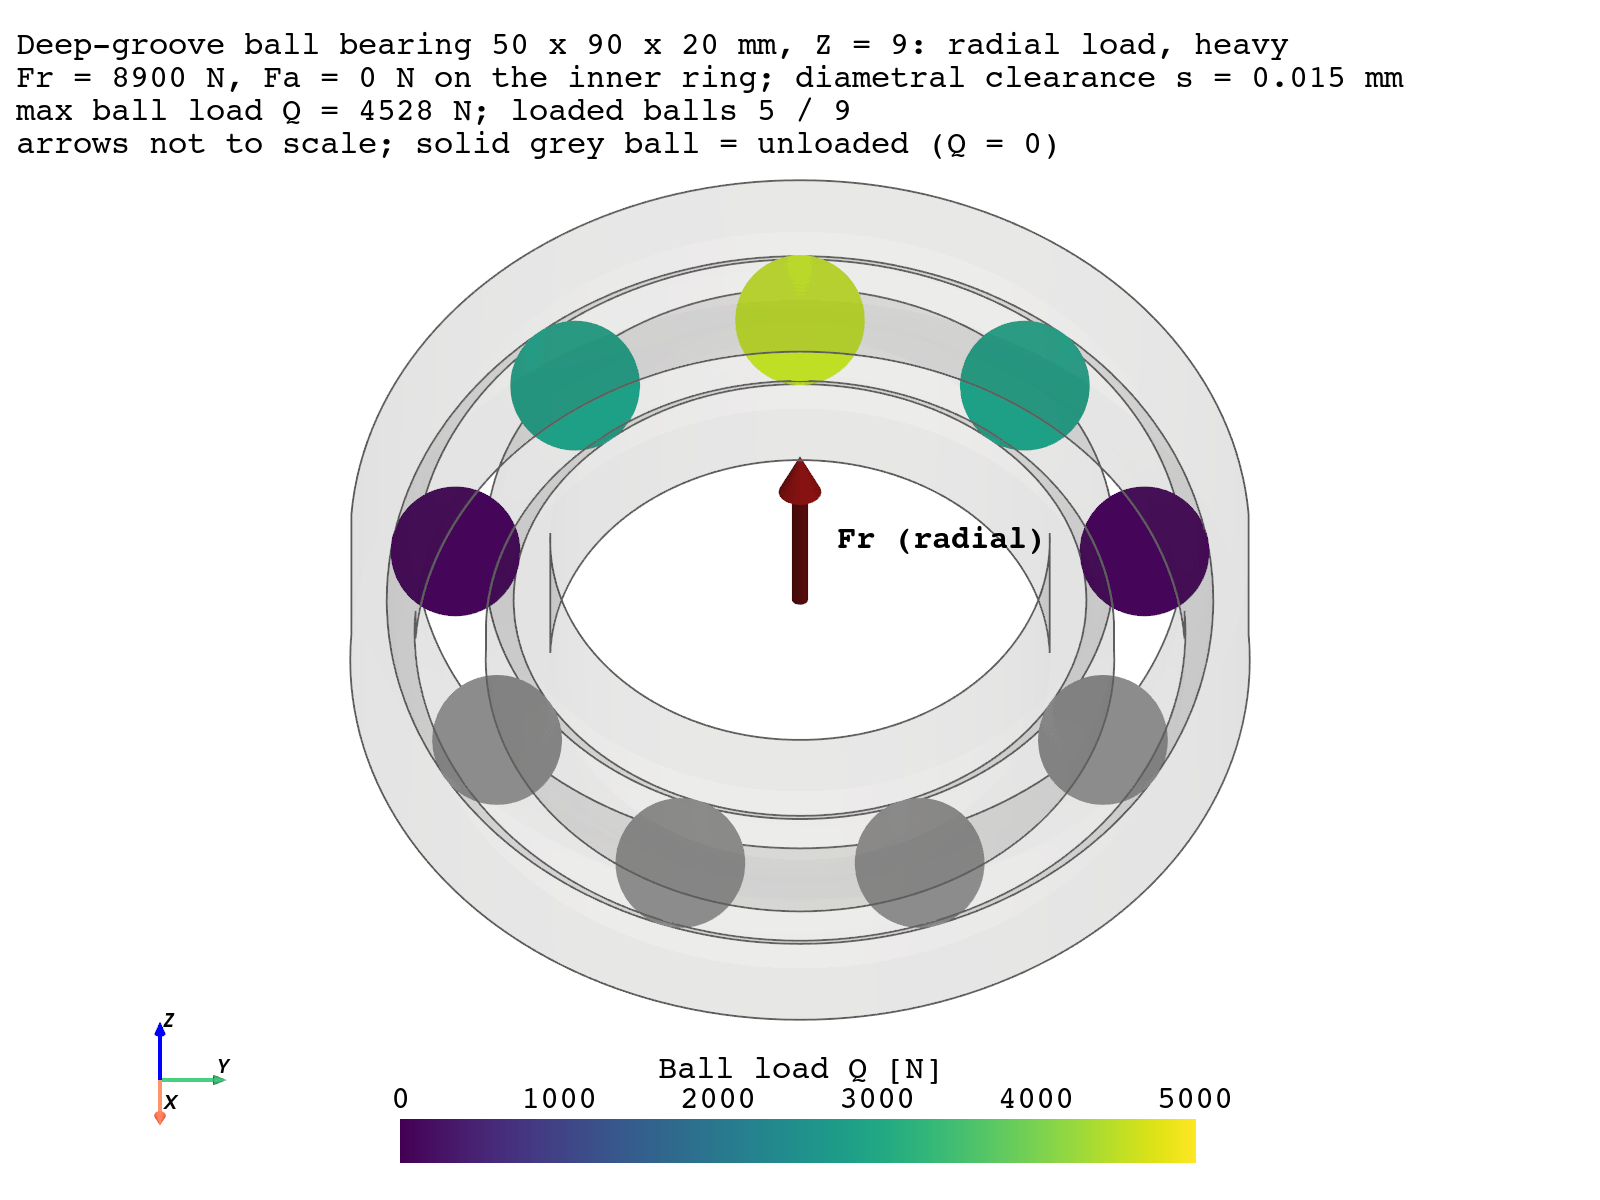

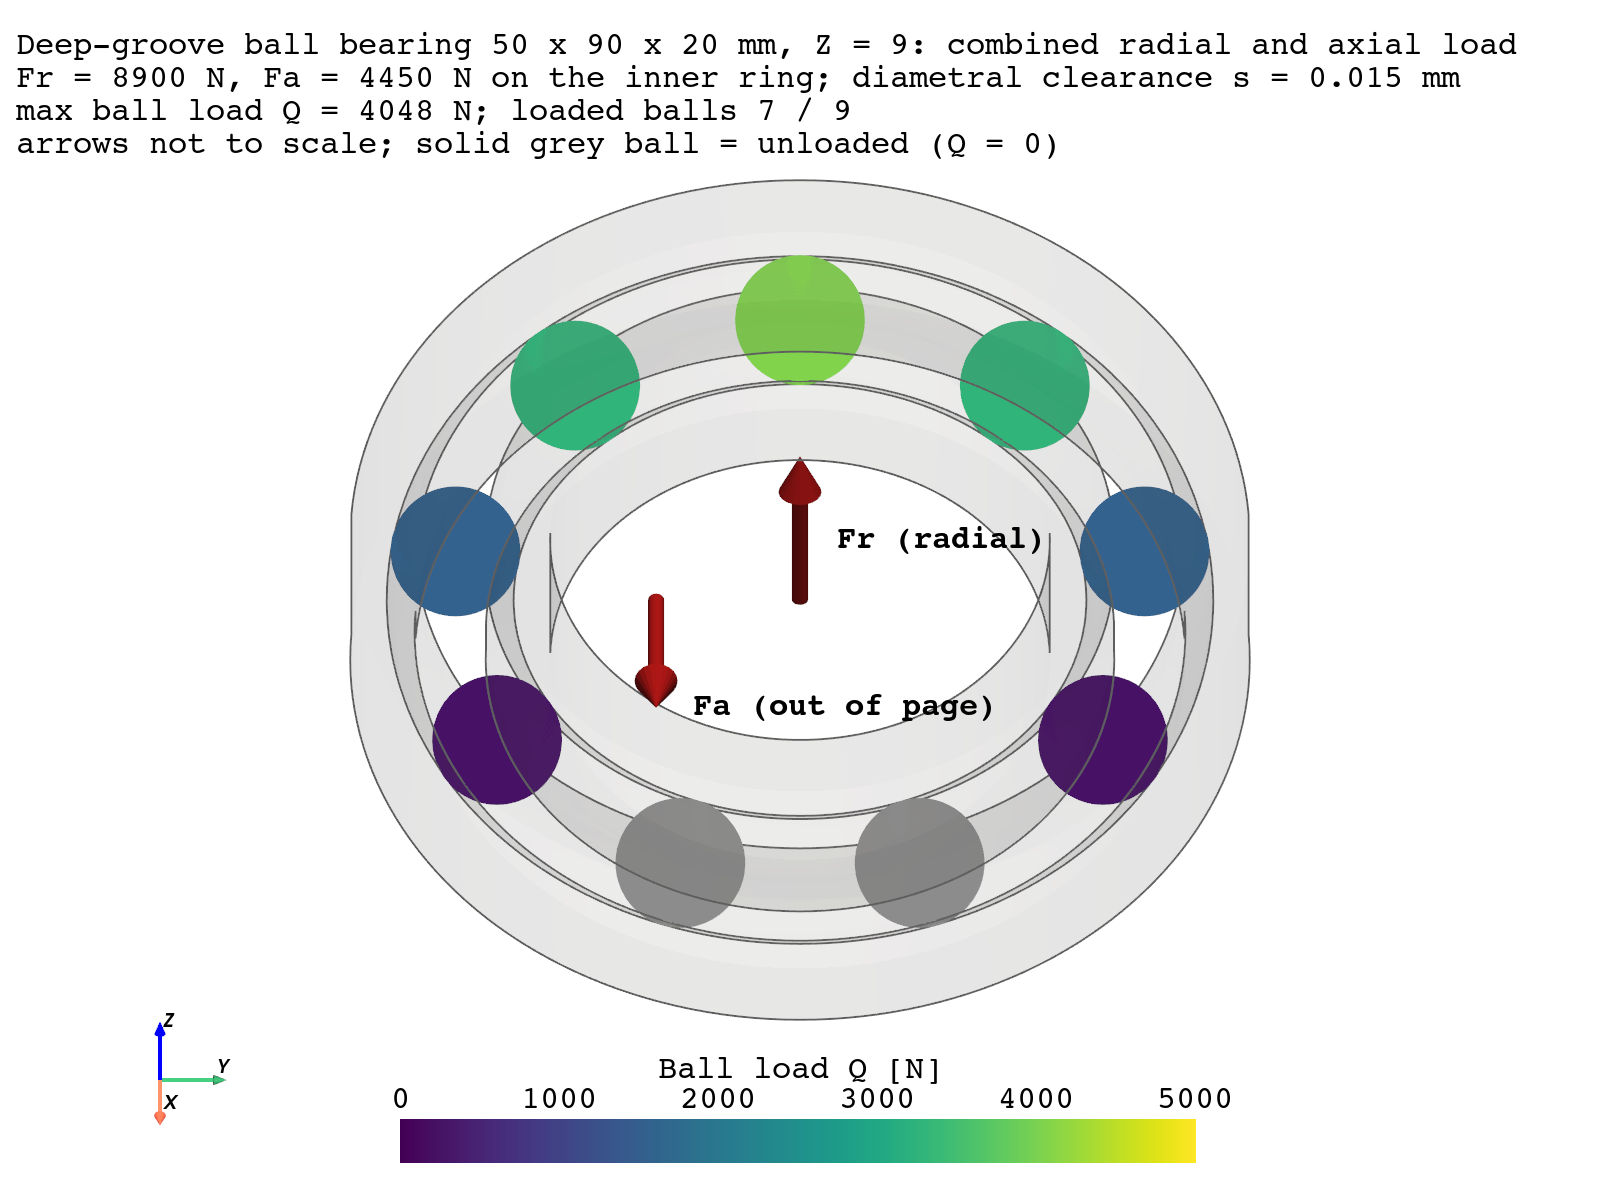

In [7]:
import pyvista as pv
from IPython.display import Image, display

from viz import bearing as vb, scene as vs

pv.set_jupyter_backend("static")                          # committed outputs are PNG only (D-0022)
VIZ = RESULTS / "viz"                                     # git-ignored (D-0020)
CASE_TEXT = {"radial_moderate": "radial load, moderate", "radial_heavy": "radial load, heavy",
             "combined": "combined radial and axial load"}

solved = {}                                               # section 1 keeps records only: solved again (ms)
for name, load in cd.LOADS.items():
    bearing = cd.build_bearing(load["s"])
    solved[name] = bearing, ISO16281BallSolver().solve_contact(
        bearing, Fr_xz=load["Fr"], Fr_xy=0.0, Fa=load["Fa"], delta_r_init=0.0, delta_a_init=0.0, psi=0.0, phi_Fr=0.0)
scenes = {name: vb.bearing_scene(b, r, case=CASE_TEXT[name]) for name, (b, r) in solved.items()}
clim = vs.clim_of(list(scenes.values()), vb.FIELDS)       # common limits of the three load cases
for name, scene in scenes.items():
    vs.save(scene, vb.FIELDS, VIZ, name, clim=clim)
for name in scenes:                                       # ball load Q [N]
    display(Image(filename=str(VIZ / f"{name}_Q.png")))

Hertz pressure $p_0$ at the inner and the outer contact of every loaded ball (one scale for both
raceways; ellipses enlarged, factor in the figure), and the contact angle of the combined case
(0 deg for every loaded ball of the two radial cases).

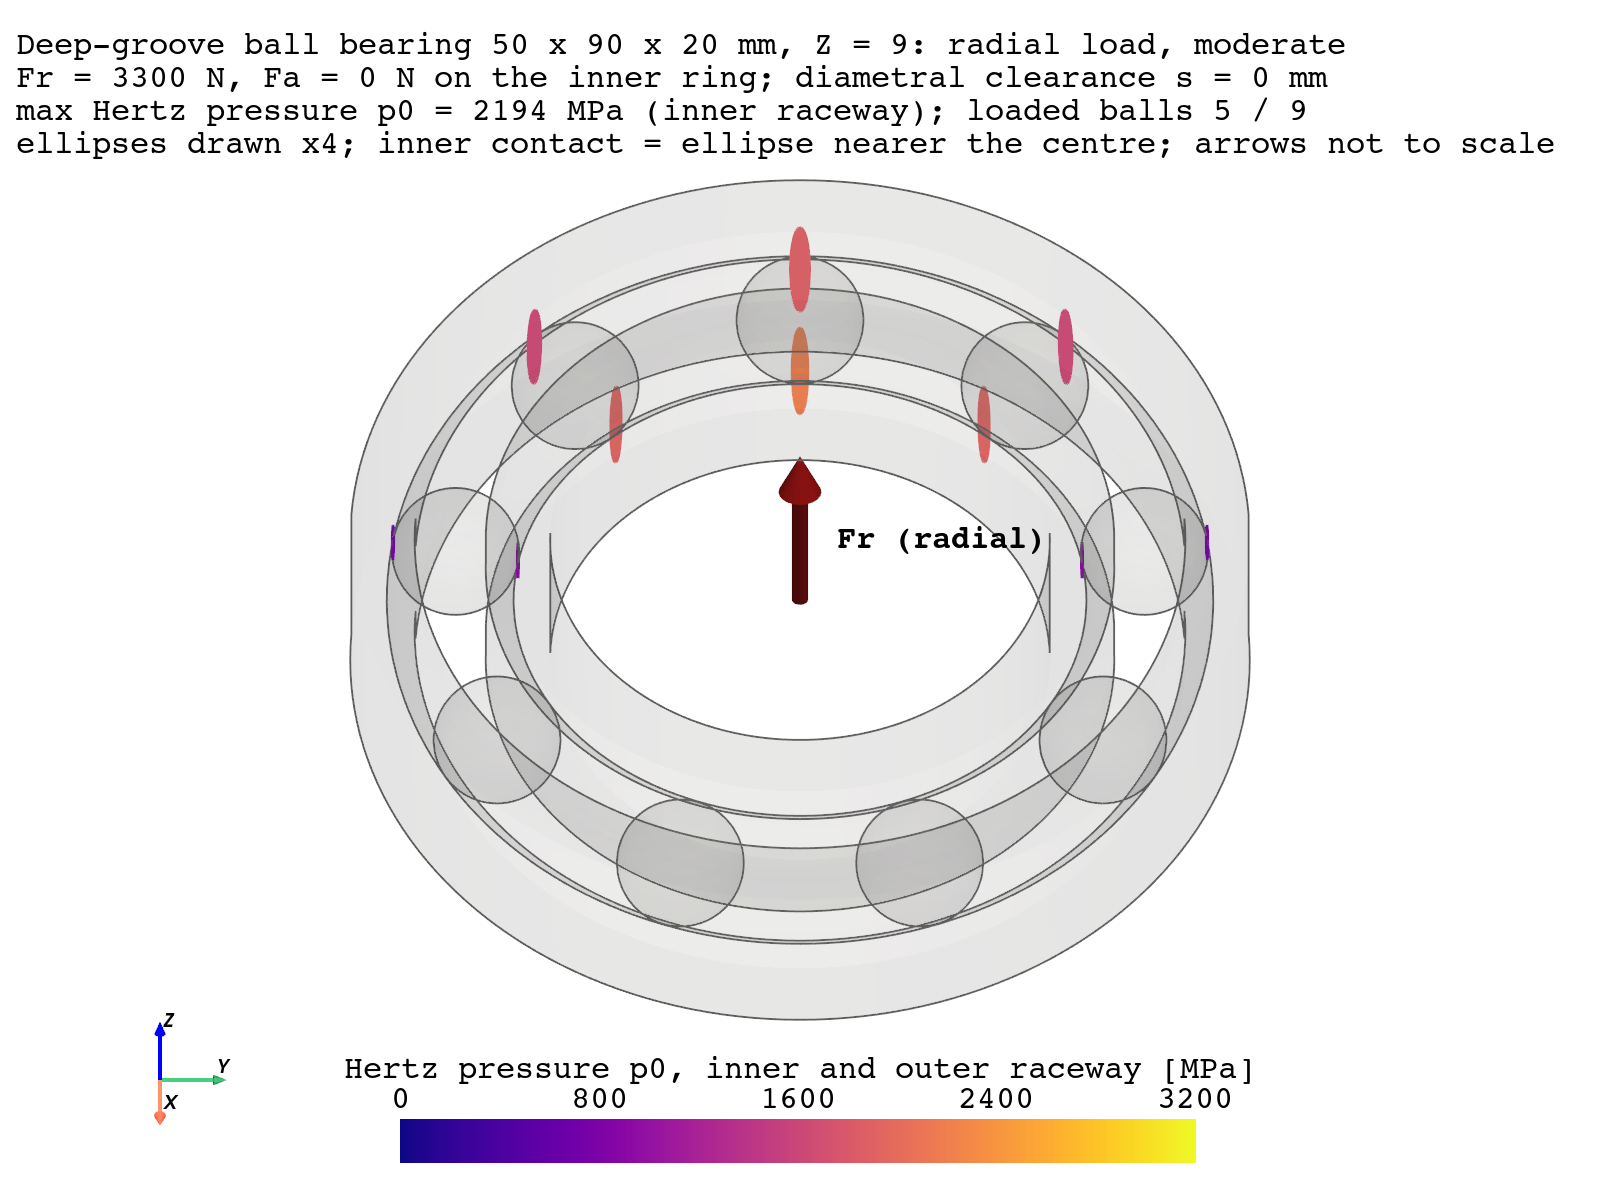

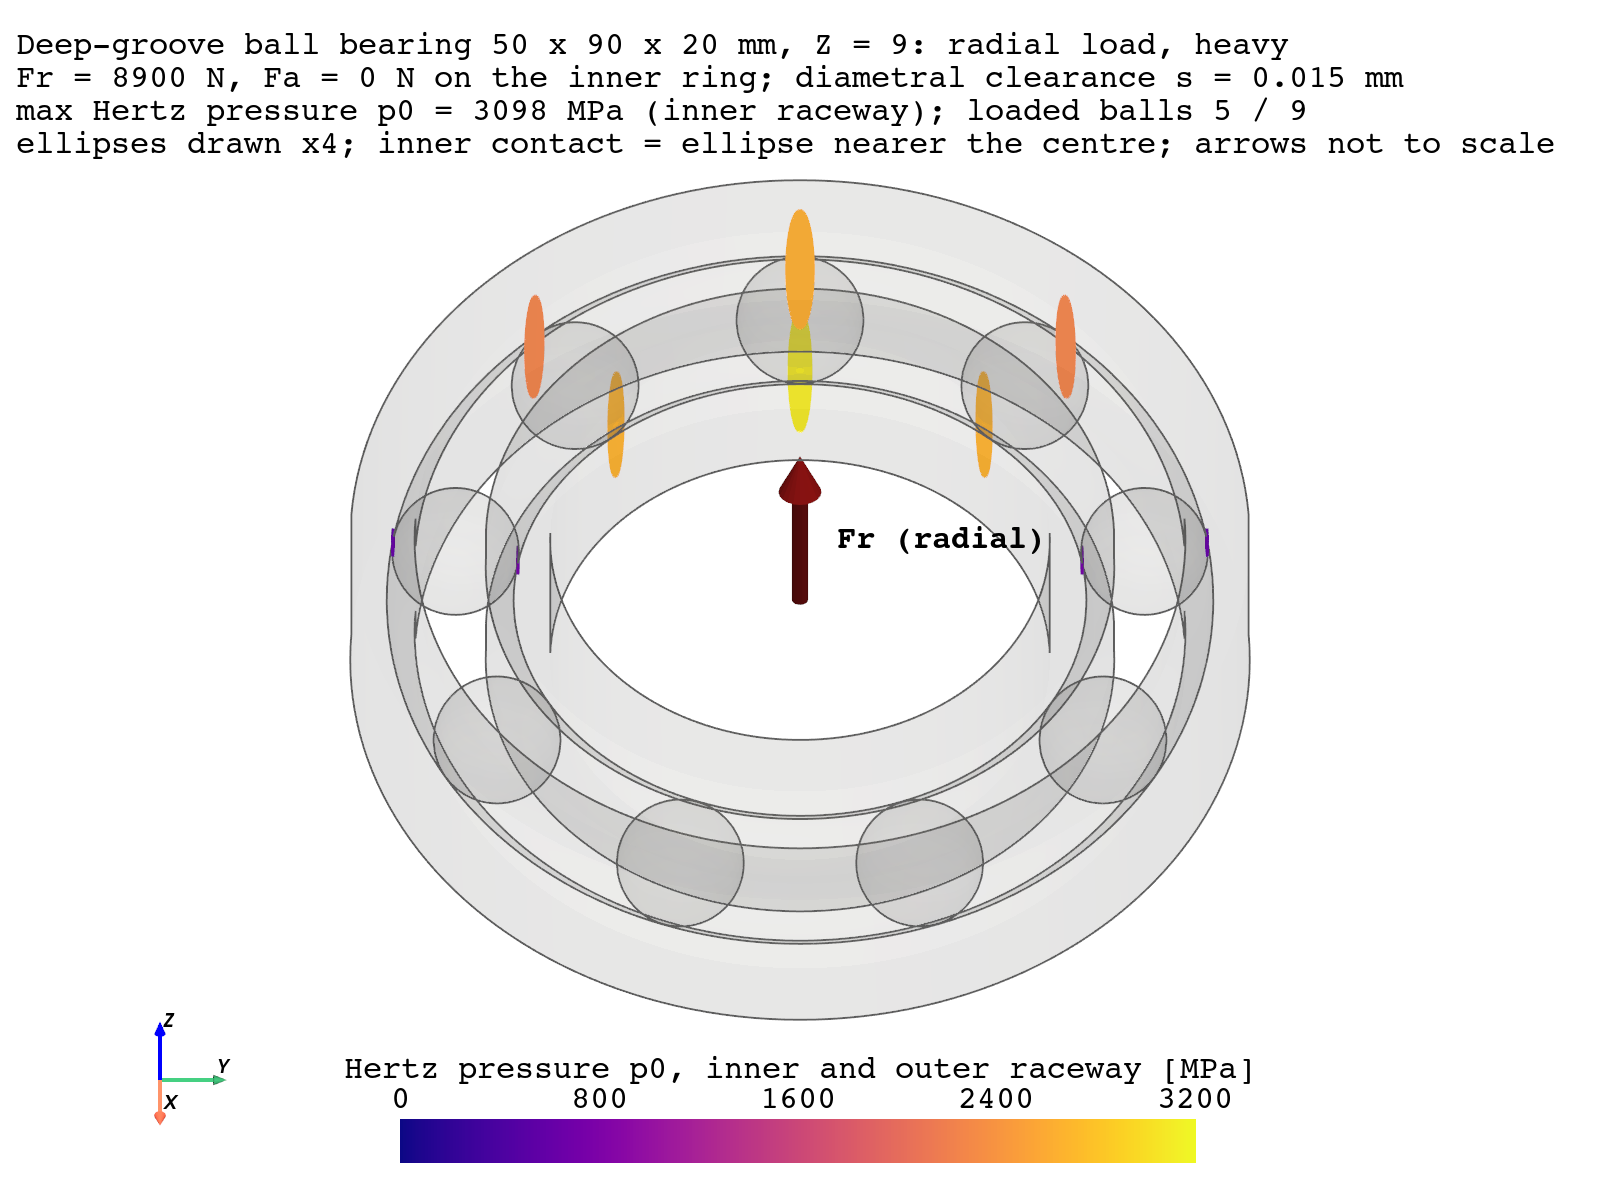

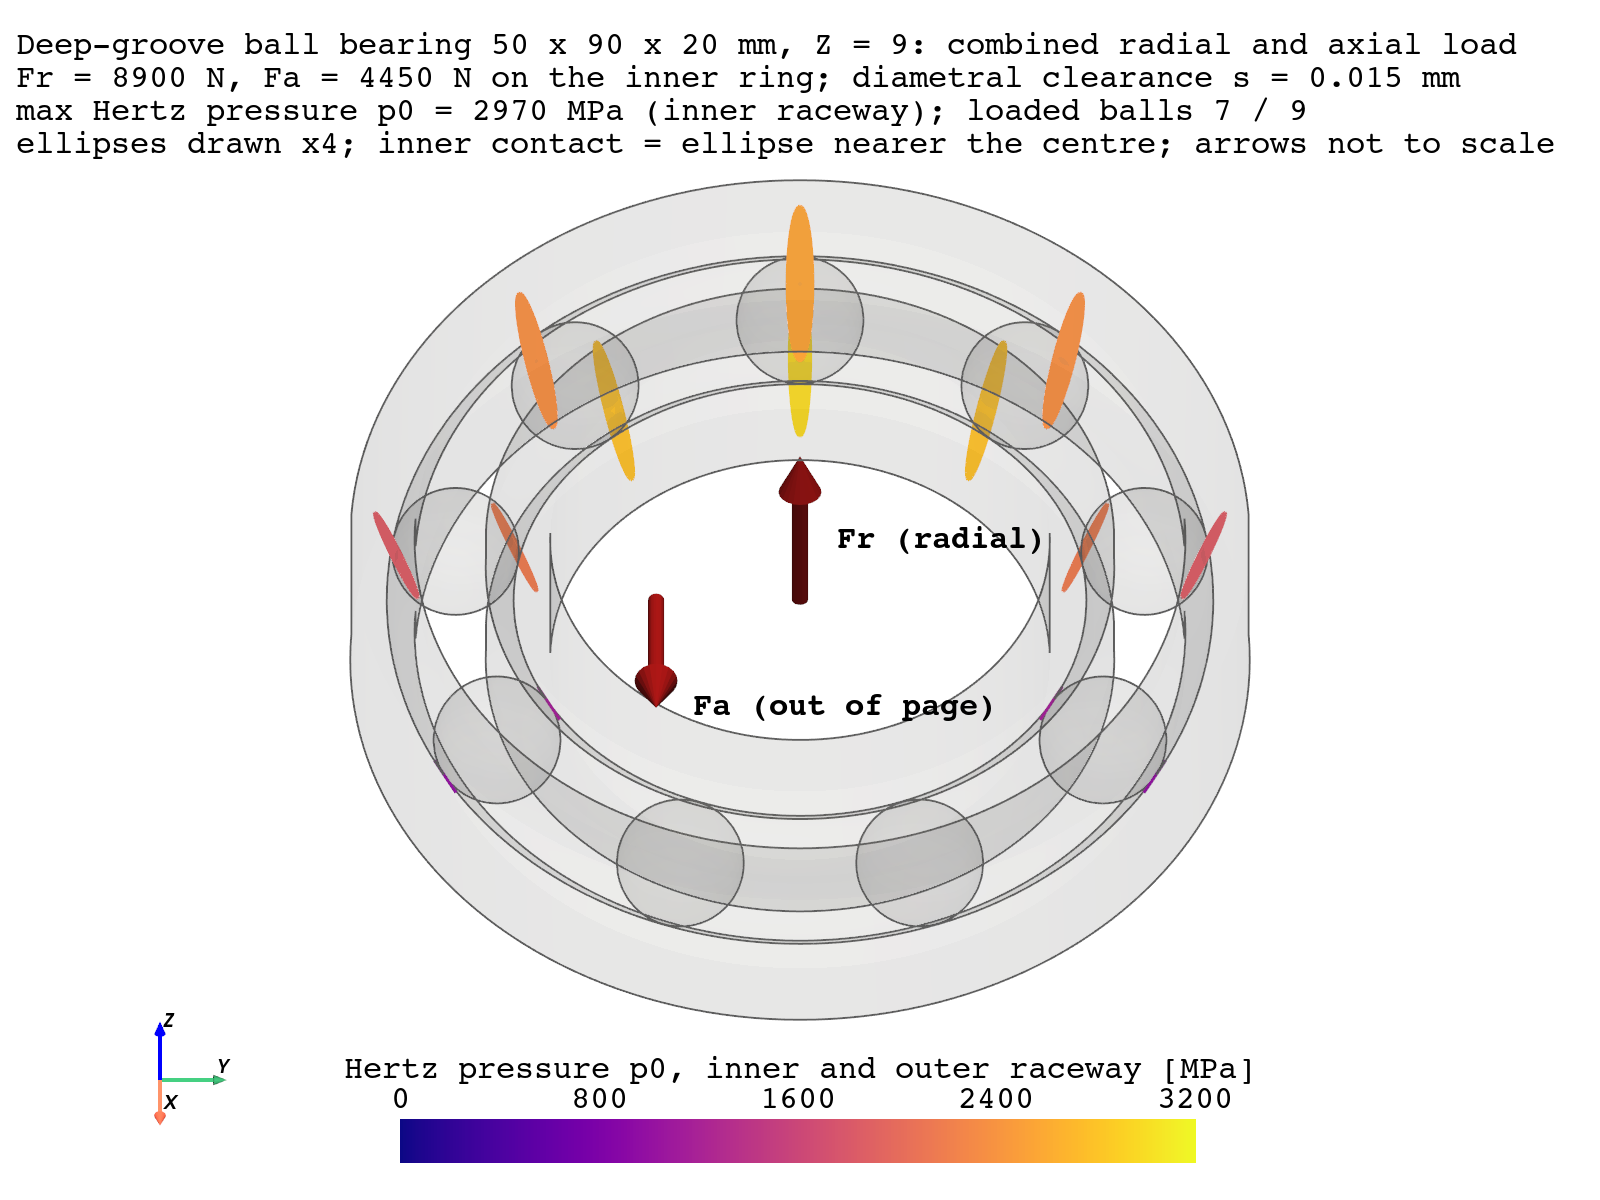

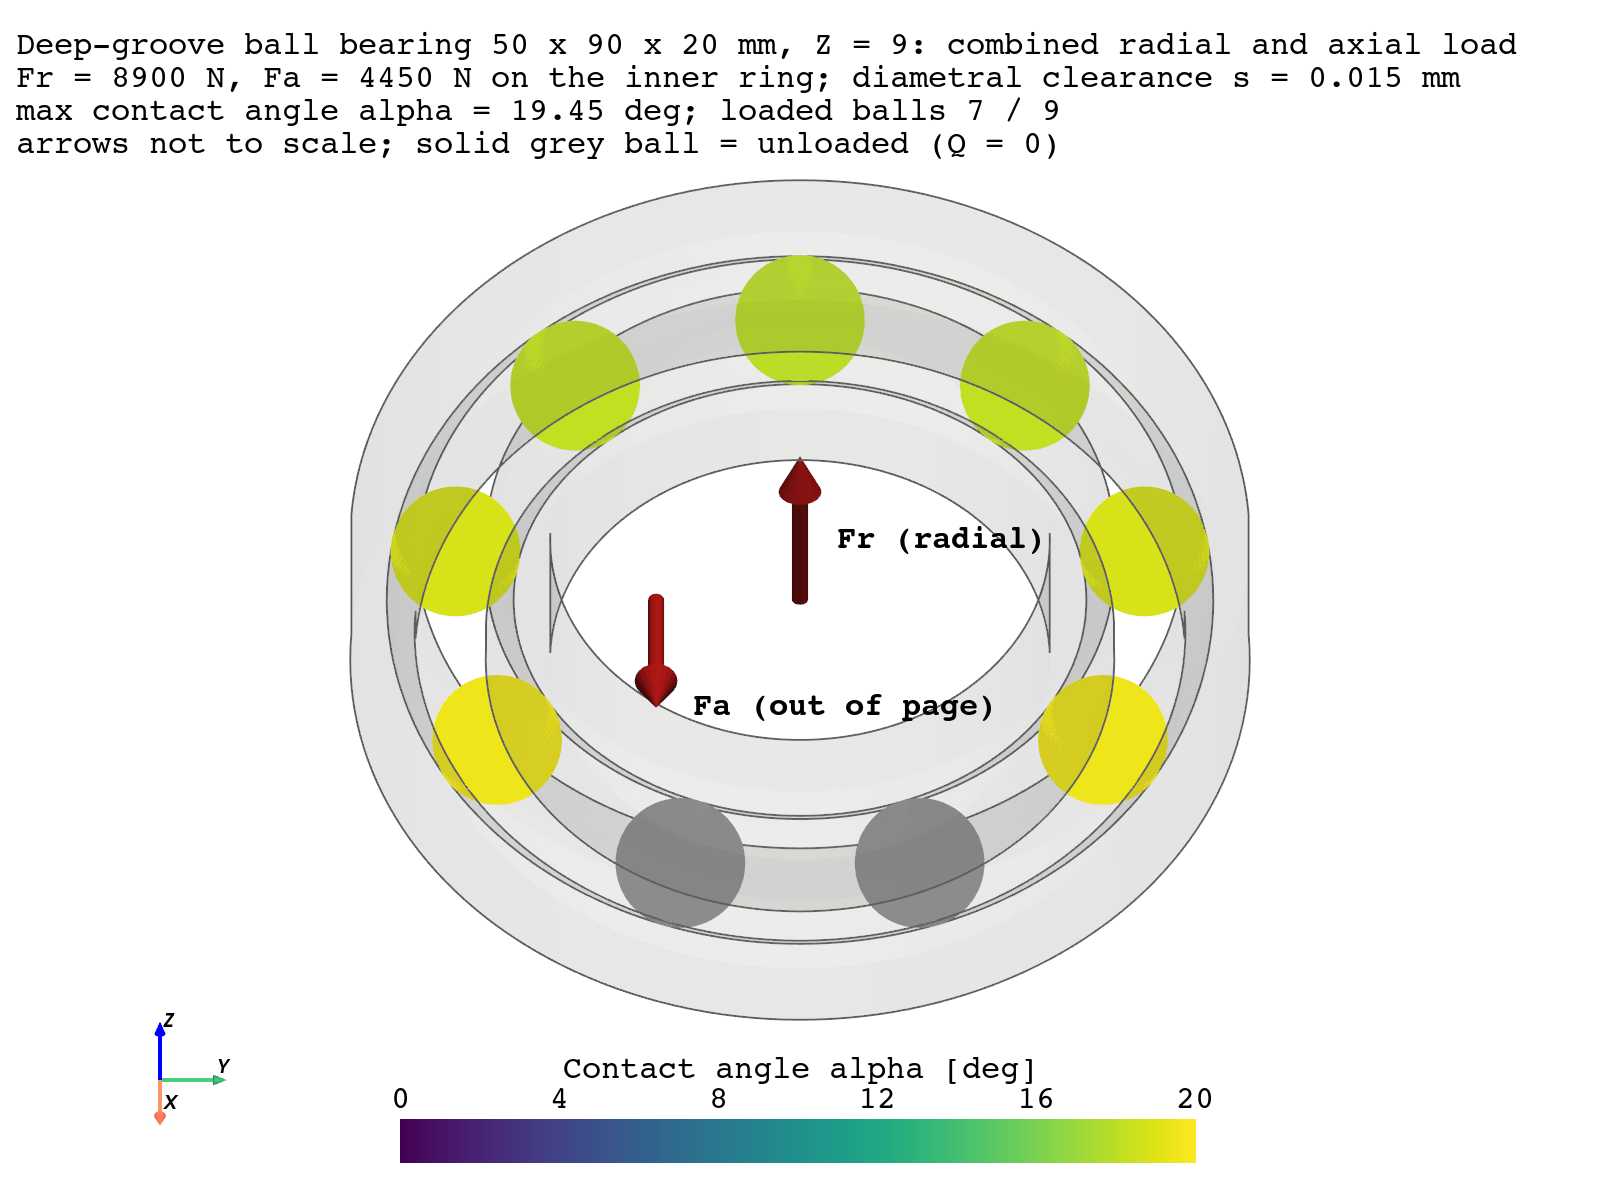

In [8]:
for shown in ("radial_moderate_p0", "radial_heavy_p0", "combined_p0", "combined_alpha"):
    display(Image(filename=str(VIZ / f"{shown}.png")))

Axial section through the most loaded ball, contact ellipses at true size: under radial load both
contacts sit on the groove bottom; the axial load moves them to opposite flanks, and the contact
line through the ball centre shows $\alpha_j$. The ring shoulders are a drawing value (AxisForge
has no shoulder geometry).

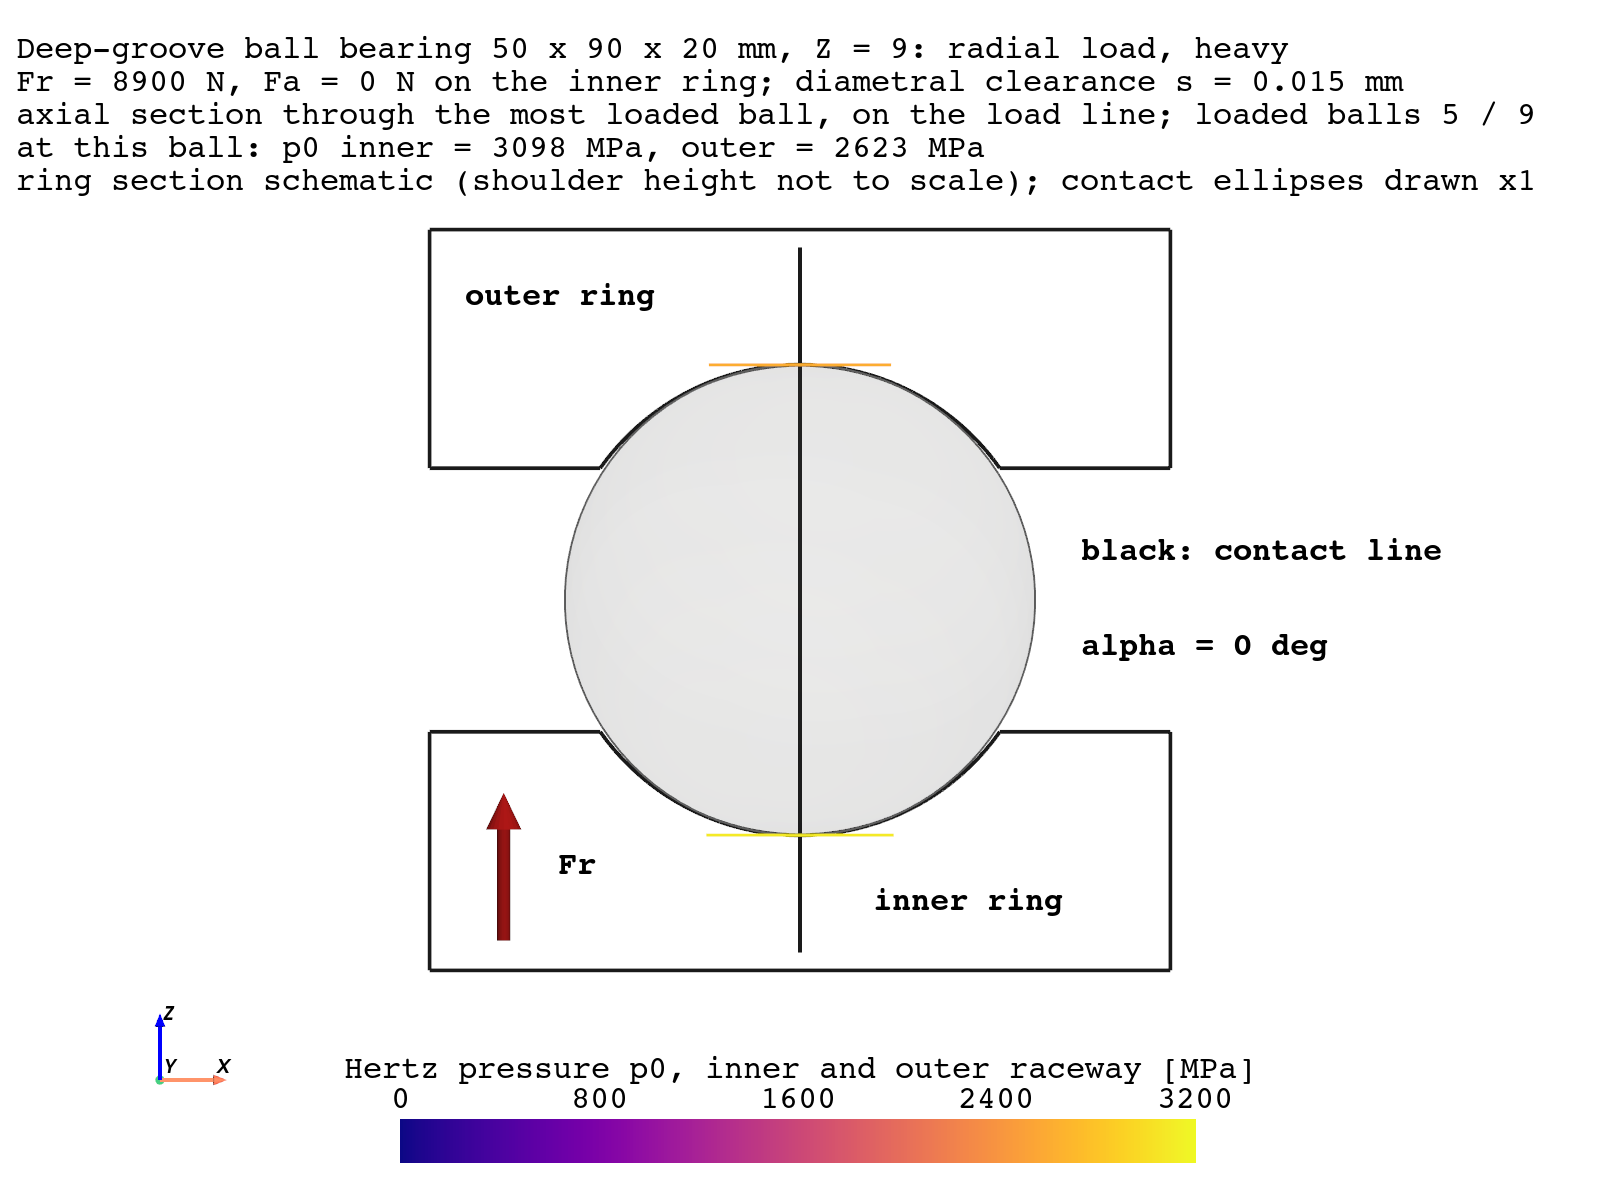

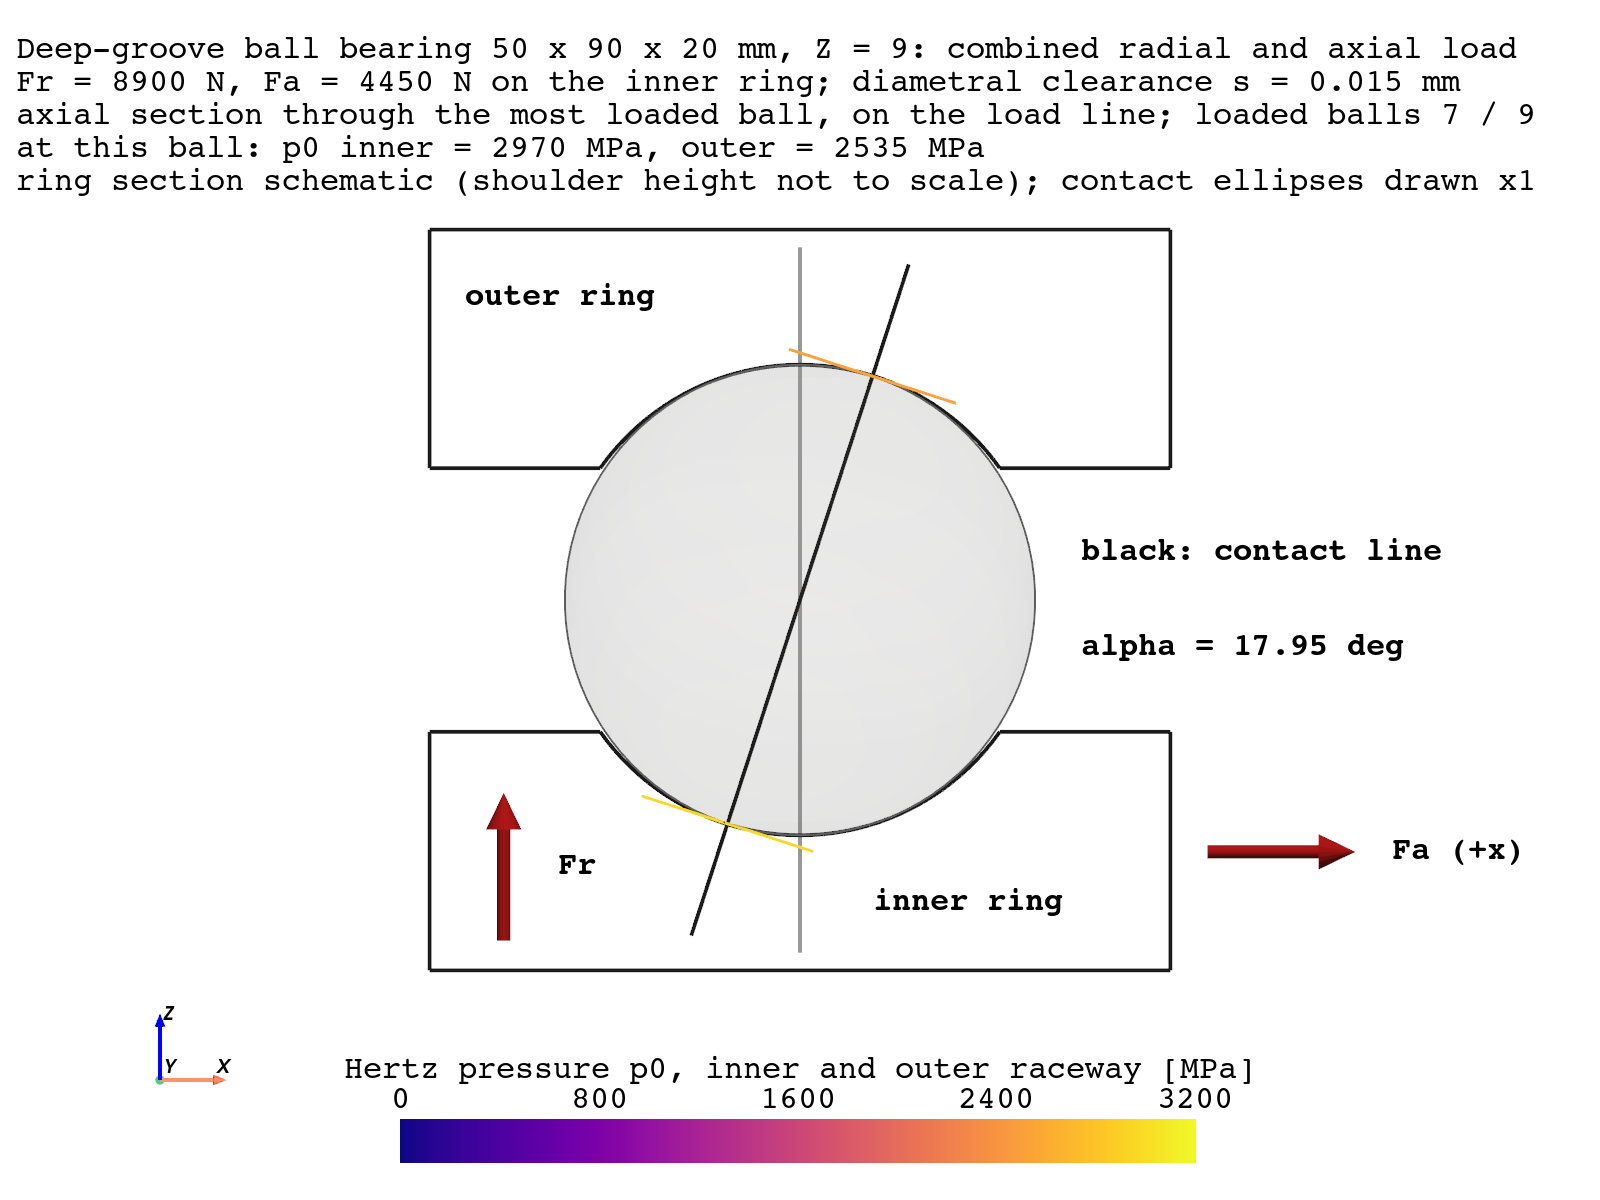

In [9]:
for name in ("radial_heavy", "combined"):
    side = vb.bearing_scene(*solved[name], case=CASE_TEXT[name], view="side", ellipse_scale=1.0)
    vs.save(side, {"p0": vb.FIELDS["p0"]}, VIZ, f"{name}_side", clim=clim)
    display(Image(filename=str(VIZ / f"{name}_side_p0.png")))

## 6. One contact solved with SlipPY: pressure against the Hertz ellipse (PyVista)

The most loaded ball of `radial_heavy` on the inner raceway, solved as a smooth dry static step
through the bridge (`slippy_bridge.contact.static_step.run`, bridge default grid and domain, a
few seconds). The pressure is kept in memory and in `results/viz/*.vtm`; SlipPY's own output files
go to a temporary folder. Hill view: height = pressure. Top view: SlipPY minus Hertz on the same
nodes. The difference is edge discretisation (one grid node at the contact edge) plus the effect
of the finite periodic domain; both solutions share the half-space assumption, so the agreement
checks the numerical method, not the Hertz model. No criterion is asserted here.

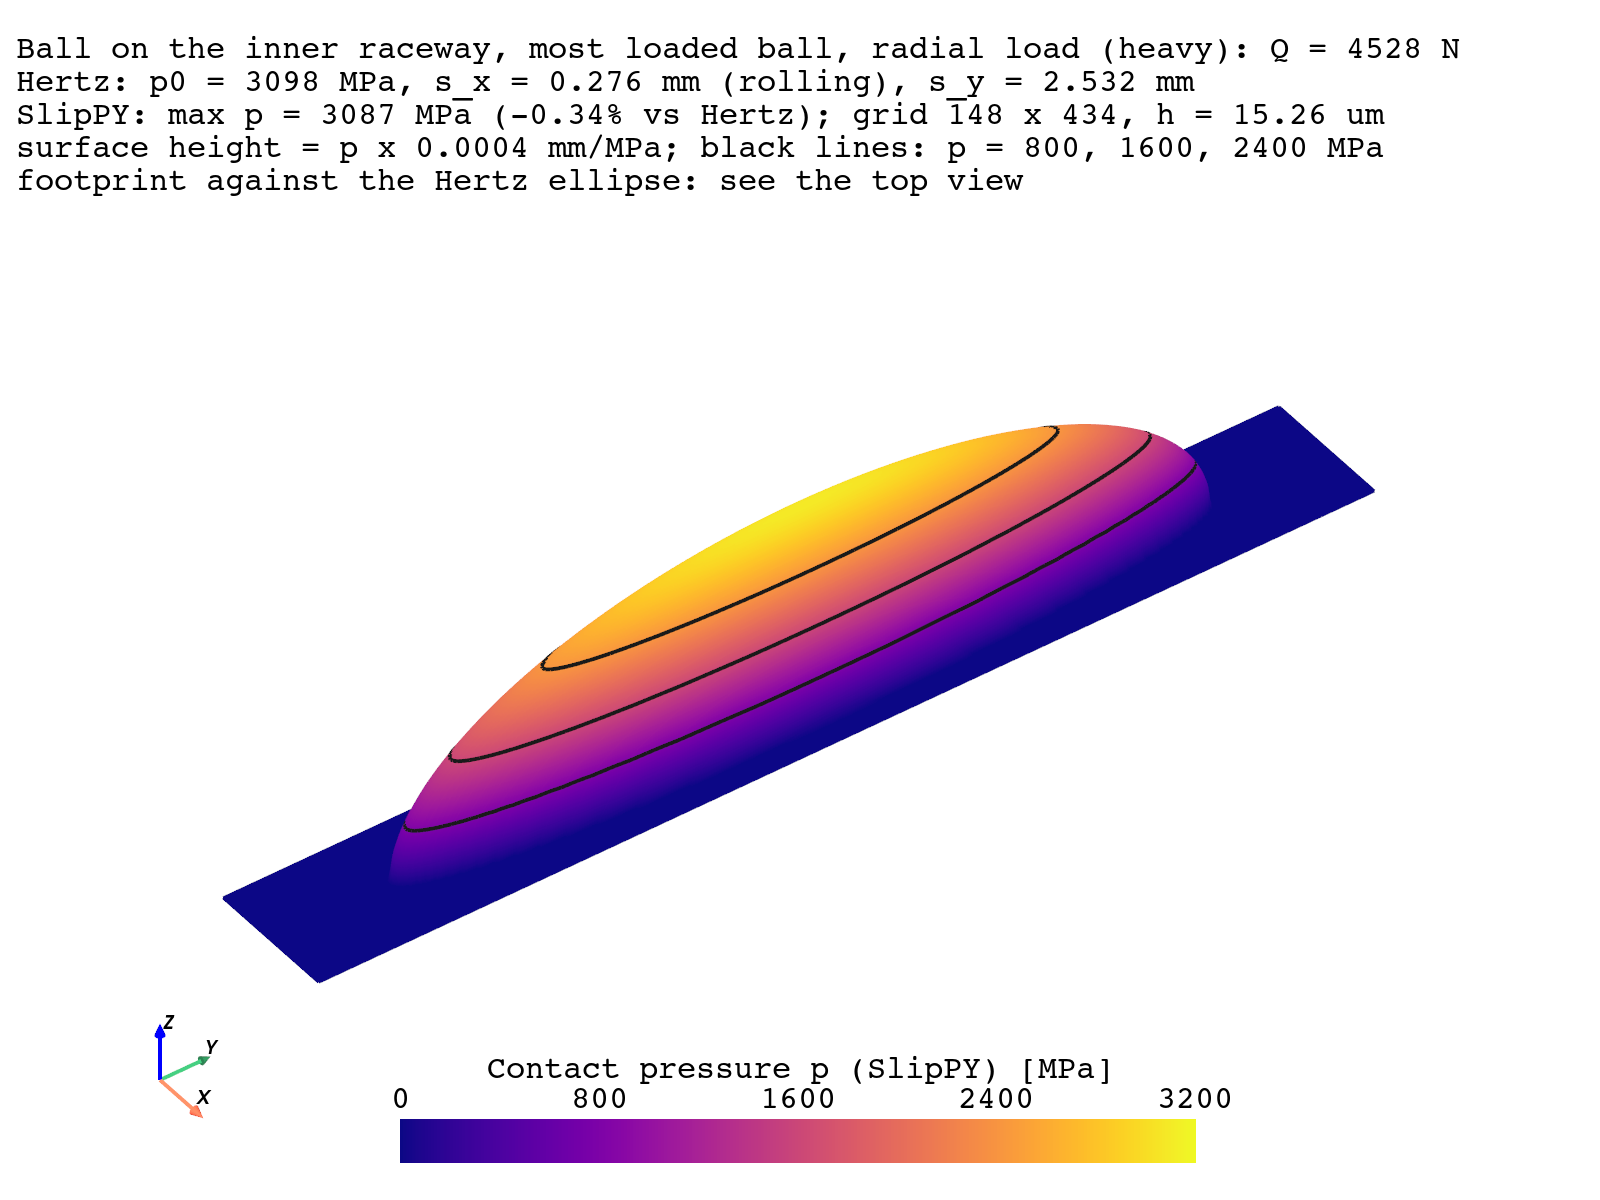

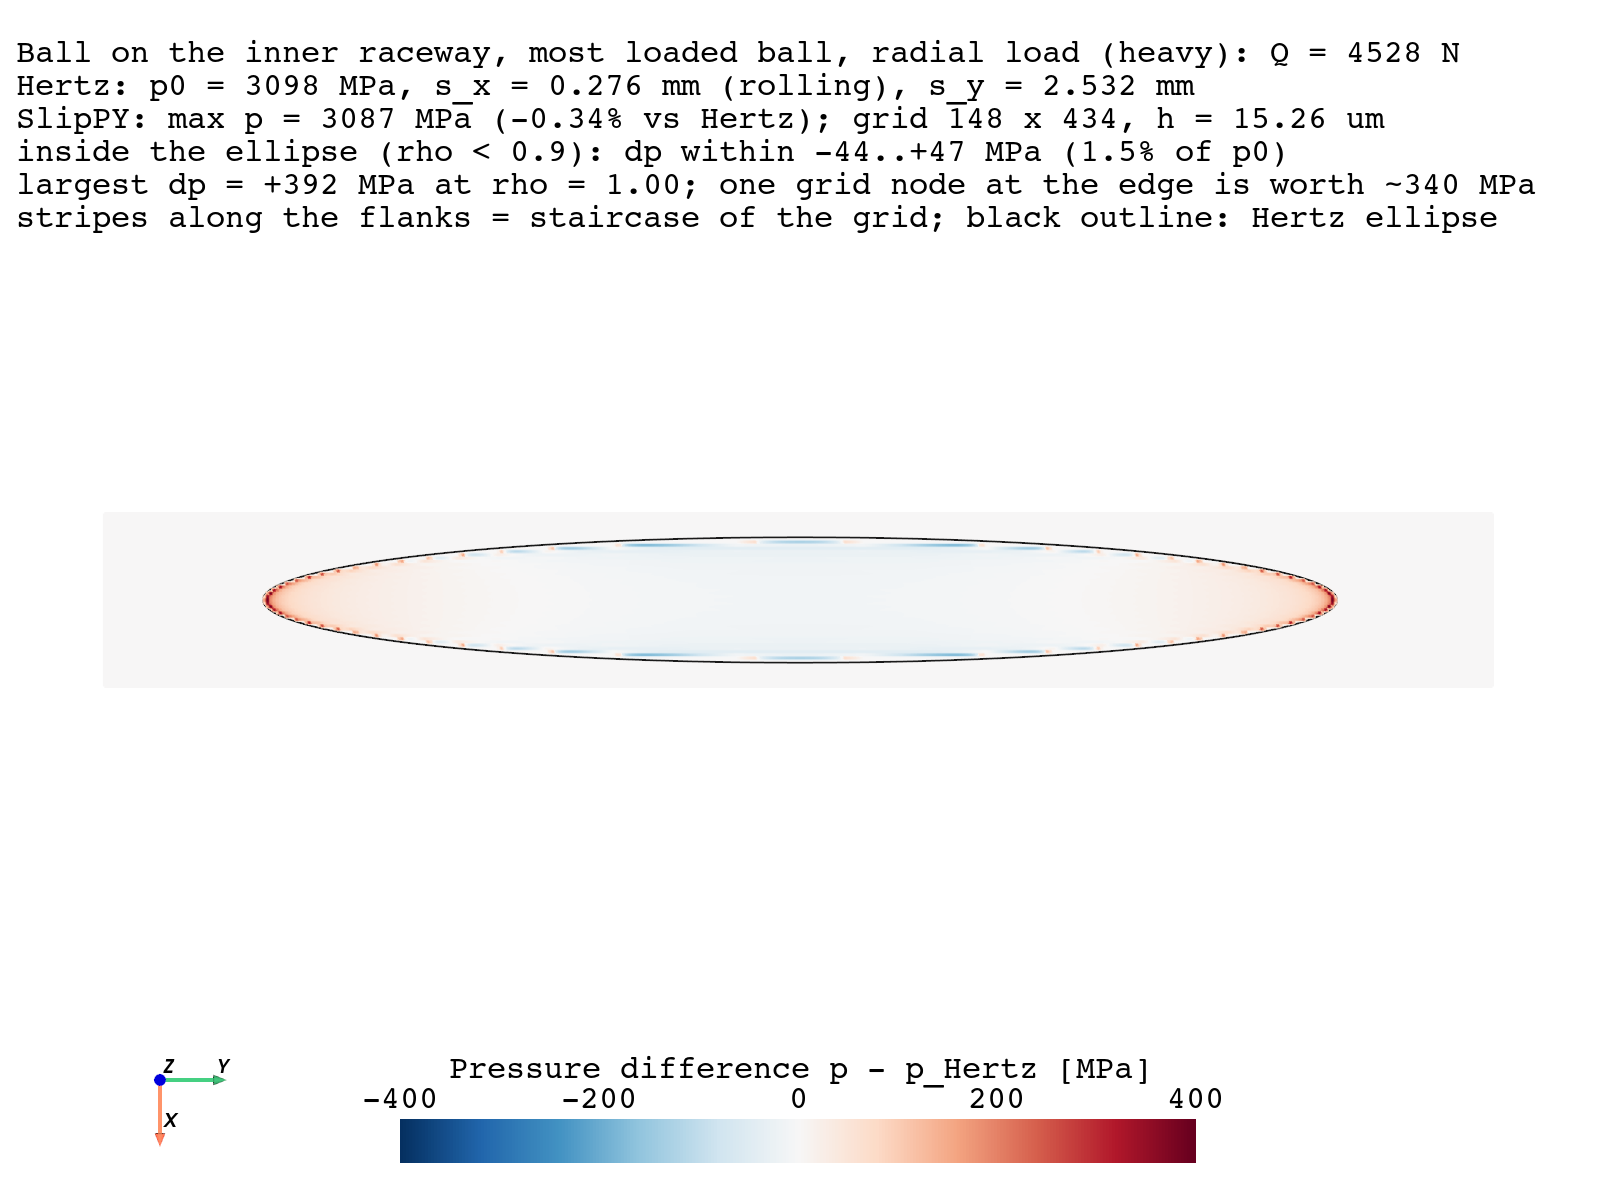

In [10]:
import tempfile

from slippy_bridge.contact import Grid, pair, static_step

from viz import contact as vc

contact = contacts(*solved["radial_heavy"], races=("inner",), elements="max")[0]
grid = Grid.around(contact.case)                          # bridge defaults
with tempfile.TemporaryDirectory() as tmp:
    record, p = static_step.run(contact, pair(contact.case, grid), grid, tmp)
CONTACT_TEXT = "Ball on the inner raceway, most loaded ball, radial load (heavy)"
hill = vc.contact_scene(contact, grid, p, case=CONTACT_TEXT)
top = vc.contact_scene(contact, grid, p, case=CONTACT_TEXT, view="top")
vs.save(hill, {"p": vc.FIELDS["p"]}, VIZ, "contact_inner_radial_heavy")
vs.save(top, vc.FIELDS, VIZ, "contact_inner_radial_heavy_top")
for shown in ("contact_inner_radial_heavy_p", "contact_inner_radial_heavy_top_dp"):
    display(Image(filename=str(VIZ / f"{shown}.png")))